In [1]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
# Futures Curve & Term Structure Monitor
# Source  : yfinance (CME/NYMEX continuous contracts)
# Markets : WTI crude oil (CL=F) + Henry Hub nat gas (NG=F)
# Focus   : Front-month price history + M1-M2 roll spread
#           as a proxy for curve shape (contango/backwardation)
#
# Design note: full 12-month forward curves are not reliably
# available via yfinance. The M1-M2 spread captures the most
# actionable part of the term structure — whether the market
# is rewarding or penalizing holders of front-month contracts.
# ─────────────────────────────────────────────────────────────

# REMINDER: UPDATE M2 FUTURES TICKERS MONTHLY 

# Contract Month Codes: https://www.cmegroup.com/month-codes.html
# January: F // February: G // March: H // April: J
# May: K // June: M // July: N // August: Q
# September: U // October: V // November: X // December: Z


# Standard library
import sys
import os
from pathlib import Path
import datetime as dt

# Data handling
import pandas as pd
import numpy as np

# Market data
import yfinance as yf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

CHART_DIR = PROJECT_ROOT / "charts"
DATA_DIR  = PROJECT_ROOT / "data"

# ── Tickers ───────────────────────────────────────────────────
# Continuous front-month contracts (M1)
WTI_M1_TICKER = "CL=F"   # WTI crude — NYMEX
NG_M1_TICKER  = "NG=F"   # Henry Hub natural gas — NYMEX

# Second-month continuous contracts (M2)
# yfinance exposes these via offset tickers on some builds
# We handle unavailability gracefully in Cell 4
# REMINDER: UPDATE EACH MONTH
WTI_M2_TICKER = "CLZ26.NYM"  # update month code each quarter CL<month code><year>.NYM <exchange>
NG_M2_TICKER  = "NGZ26.NYM"  # update month code each quarter

# ── Check current front month for both contracts ──────────────
for label, tkr in [("WTI", "CL=F"), ("NG", "NG=F")]:
    info = yf.Ticker(tkr).info
    print(f"{label}: {info.get('shortName','N/A')}  "
          f"| underlying: {info.get('underlyingExchangeSymbol','N/A')}  "
          f"| expires: {info.get('expireIsoDate','N/A')[:10]}")

# ── Date configuration ────────────────────────────────────────
PRICE_START        = "2022-01-01"   # 3+ years of history
END_DATE           = dt.date.today()
SPREAD_WINDOW_DAYS = 252            # rolling window for spread stats (~1yr)
RECENT_DAYS        = 365 * 2        # chart focus window (2 years)

# ── Cache paths ───────────────────────────────────────────────
WTI_CACHE = DATA_DIR / "wti_price_cache.csv"
NG_CACHE  = DATA_DIR / "ng_price_cache.csv"

print("=" * 58)
print("Tool 4 — Futures Curve & Term Structure Monitor")
print("=" * 58)
print(f"WTI M1 ticker  : {WTI_M1_TICKER}")
print(f"NG  M1 ticker  : {NG_M1_TICKER}")
print(f"Price history  : {PRICE_START} -> {END_DATE}")
print(f"Spread window  : {SPREAD_WINDOW_DAYS} trading days")
print(f"WTI cache      : {WTI_CACHE.name}")
print(f"NG  cache      : {NG_CACHE.name}")
print("=" * 58)


WTI: Crude Oil Nov 26  | underlying: CLX26.NYM  | expires: 2026-10-20
NG: Natural Gas Nov 26  | underlying: NGX26.NYM  | expires: 2026-10-28
Tool 4 — Futures Curve & Term Structure Monitor
WTI M1 ticker  : CL=F
NG  M1 ticker  : NG=F
Price history  : 2022-01-01 -> 2026-10-10
Spread window  : 252 trading days
WTI cache      : wti_price_cache.csv
NG  cache      : ng_price_cache.csv


In [2]:
# ============================================================
# CELL 2 — Fetch front-month price history with caching
# ============================================================
# Downloads WTI (CL=F) and Henry Hub (NG=F) front-month
# continuous contract price history.
#
# Caching pattern (same as WTI_Brent_Monitor):
#   First run  : full download from PRICE_START -> saves CSV
#   Subsequent : loads CSV + fetches only new days (~2 sec)
#
# Why continuous front-month contracts:
#   CL=F and NG=F auto-roll to the next contract on expiry.
#   This gives a clean unbroken price history without gaps.
#   The roll creates a small discontinuity each month which
#   is visible as an occasional 1-day price jump — this is
#   normal and expected, not a data error.
# ─────────────────────────────────────────────────────────────

def fetch_price_with_cache(
        ticker: str,
        cache_path: Path,
        start: str,
        end: dt.date,
        price_col: str = "Close",
) -> pd.DataFrame:
    """
    Fetch daily closing prices for a ticker via yfinance,
    using a local CSV cache for speed on repeat runs.

    Parameters
    ----------
    ticker     : yfinance ticker string e.g. 'CL=F', 'NG=F'
    cache_path : Path to local CSV cache file
    start      : earliest date to fetch 'YYYY-MM-DD'
    end        : latest date (today usually)
    price_col  : which OHLCV column to keep (default Close)

    Returns
    -------
    pd.DataFrame with columns: date, price
    Daily frequency, sorted ascending, NaNs dropped.
    """
    end_str = end.strftime("%Y-%m-%d")

    # ── Attempt to load from cache ────────────────────────────
    if cache_path.exists():
        df_cache = pd.read_csv(cache_path, parse_dates=["date"])
        df_cache = df_cache.sort_values("date").reset_index(drop=True)

        last_cached = df_cache["date"].max().date()
        days_stale = (end - last_cached).days

        if days_stale <= 1:
            print(f" [{ticker}] Cache current "
                  f"(last: {last_cached}) - skipping download")
            return df_cache
        fetch_start = (
            last_cached + dt.timedelta(days=1)
        ).strftime("%Y-%m-%d")
        print(f" [{ticker}] Cache stale by {days_stale} days - "
              f"fetching {fetch_start} -> {end_str}")
        is_incremental = True
    
    else:
        fetch_start = start
        df_cache = None
        is_incremental = False
        print(f"  [{ticker}] No cache — "
              f"full download {fetch_start} -> {end_str}")
        
    # ── Download from yfinance ────────────────────────────────
    try:
        raw = yf.download(
            ticker,
            start = fetch_start,
            end = end_str,
            interval = "1d",
            auto_adjust = True,
            progress = False,
        )
    except Exception as e:
        raise RuntimeError(f"yfinance download failed for {ticker}: {e}")
    
    if raw.empty:
        if is_incremental and df_cache is not None:
            print(f" [{ticker}] No new data - using cached data")
            return df_cache
        raise ValueError(
            f"yfinance returned no data for {ticker} "
            f"({fetch_start} -> {end_str})"
        )
    
    # ── Parse and clean ───────────────────────────────────────
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    df_new = raw[[price_col]].copy()
    df_new.index = pd.to_datetime(df_new.index)
    df_new = df_new.reset_index()
    df_new.columns = ["date", "price"]

    dates = pd.to_datetime(df_new["date"])
    if dates.dt.tz is not None:
        df_new["date"] = dates.dt.tz_convert(None)
    else:
        df_new["date"] = dates.dt.tz_localize(None)
    
    df_new = df_new.dropna(subset=["price"])
    df_new = df_new[df_new["price"] != 0]

    # ── Merge with cache if incremental ──────────────────────
    if is_incremental and df_cache is not None:
        df_combined = pd.concat(
            [df_cache, df_new], ignore_index=True
        )
        df_combined = df_combined.drop_duplicates(
            subset=["date"], keep="last"
        )
    else:
        df_combined = df_new
    
    df_combined = (df_combined
                   .sort_values("date")
                   .reset_index(drop=True))
    
    # ── Save updated cache ────────────────────────────────────
    df_combined.to_csv(cache_path, index=False)
    print(f"  [{ticker}] Saved {len(df_combined):,} rows -> "
          f"{cache_path.name}")
    
    return df_combined


# ── Download WTI and Henry Hub ────────────────────────────────
print("Fetching price data...")
print()

df_wti_daily = fetch_price_with_cache(
    ticker = WTI_M1_TICKER,
    cache_path = WTI_CACHE,
    start = PRICE_START,
    end = END_DATE,
)

df_ng_daily = fetch_price_with_cache(
    ticker = NG_M1_TICKER,
    cache_path = NG_CACHE,
    start = PRICE_START,
    end = END_DATE,
)

# ── Rename price columns ──────────────────────────────────────
df_wti_daily = df_wti_daily.rename(columns={"price": "wti"})
df_ng_daily = df_ng_daily.rename(columns={"price": "ng"})

# ── Summary ───────────────────────────────────────────────────
latest_wti = df_wti_daily["wti"].iloc[-1]
latest_ng  = df_ng_daily["ng"].iloc[-1]

# ── 52 week Hi Lo ─────────────────────────────────────────────
wti_52h = df_wti_daily["wti"].tail(252).max()
wti_52l = df_wti_daily["wti"].tail(252).min()
ng_52h  = df_ng_daily["ng"].tail(252).max()
ng_52l  = df_ng_daily["ng"].tail(252).min()

print()
print("=" * 58)
print("  Price data loaded")
print("=" * 58)
print(f"  WTI daily rows  : {len(df_wti_daily):,} trading days")
print(f"  NG  daily rows  : {len(df_ng_daily):,} trading days")
print(f"  WTI date range  : "
      f"{df_wti_daily['date'].min().date()} -> "
      f"{df_wti_daily['date'].max().date()}")
print(f"  NG  date range  : "
      f"{df_ng_daily['date'].min().date()} -> "
      f"{df_ng_daily['date'].max().date()}")
print()
print(f"  WTI latest      : ${latest_wti:.2f}/bbl")
print(f"  WTI 52-week     : ${wti_52l:.2f} – ${wti_52h:.2f}")
print()
print(f"  NG  latest      : ${latest_ng:.3f}/MMbtu")
print(f"  NG  52-week     : ${ng_52l:.3f} – ${ng_52h:.3f}")
print("=" * 58)

Fetching price data...

 [CL=F] Cache current (last: 2026-10-09) - skipping download
 [NG=F] Cache stale by 8 days - fetching 2026-10-03 -> 2026-10-10
  [NG=F] Saved 1,201 rows -> ng_price_cache.csv

  Price data loaded
  WTI daily rows  : 4,976 trading days
  NG  daily rows  : 1,201 trading days
  WTI date range  : 2007-01-02 -> 2026-10-09
  NG  date range  : 2022-01-03 -> 2026-10-09

  WTI latest      : $91.85/bbl
  WTI 52-week     : $55.27 – $112.95

  NG  latest      : $3.220/MMbtu
  NG  52-week     : $2.523 – $7.460


In [3]:
# ============================================================
# CELL 3 — Rolling statistics and moving averages
# ============================================================
# Computes rolling analytical series for both WTI and NG:
#   50-day and 200-day moving averages (trend context)
#   252-day (52-week) rolling high and low (range context)
#   WTI/NG energy-equivalent ratio (substitution signal)
#
# All calculations on daily data. We resample to weekly
# at the end for alignment with Tools 1 and 3.
#
# Note on WTI/NG ratio:
#   On a pure energy-equivalent basis, 1 bbl oil = 5.8 MMbtu
#   So the energy-equivalent ratio = WTI / (NG * 5.8)
#   Ratio >> 1 means oil is expensive relative to gas
#   Ratio << 1 means gas is expensive relative to oil
#   Long-run average is roughly 8-12x on a $/MMbtu basis
#   (WTI in $/bbl divided by NG in $/MMbtu, not energy adj.)
# ─────────────────────────────────────────────────────────────

# ── Work on copies to avoid modifying cached data ────────────
df_wti = df_wti_daily.copy().sort_values("date").reset_index(drop=True)
df_ng = df_ng_daily.copy().sort_values("date").reset_index(drop=True)

# ── WTI rolling statistics ────────────────────────────────────
df_wti["ma50"] = df_wti["wti"].rolling(50, min_periods=30).mean()
df_wti["ma200"] = df_wti["wti"].rolling(200, min_periods=60).mean()
df_wti["high_52w"] = df_wti["wti"].rolling(252, min_periods=60).max()
df_wti["low_52w"] = df_wti["wti"].rolling(252, min_periods=60).min()

# 52-week percentile position: where is today vs the past year?
# 0% = at 52-week low, 100% = at 52-week high
df_wti["pctile_52w"] = (
    (df_wti["wti"] - df_wti["low_52w"])
    / (df_wti["high_52w"] - df_wti["low_52w"]) 
    * 100
)

# ── Henry Hub rolling statistics ─────────────────────────────
df_ng["ma50"]     = df_ng["ng"].rolling(50,  min_periods=30).mean()
df_ng["ma200"]    = df_ng["ng"].rolling(200, min_periods=60).mean()
df_ng["high_52w"] = df_ng["ng"].rolling(252, min_periods=60).max()
df_ng["low_52w"]  = df_ng["ng"].rolling(252, min_periods=60).min()

df_ng["pctile_52w"] = (
    (df_ng["ng"] - df_ng["low_52w"])
    / (df_ng["high_52w"] - df_ng["low_52w"])
    * 100
)

# ── Merge WTI and NG onto a common daily date spine ──────────
# Use inner merge — keeps only dates where both series
# have data (from 2022 onward, matching NG history).
# Outer merge would produce NaN-filled rows for 2007-2021
# where NG data doesn't exist — no analytical value.
df_daily = pd.merge(
    df_wti[["date", "wti", "ma50", "ma200", "high_52w", "low_52w", "pctile_52w"]],
    df_ng[["date", "ng", "ma50", "ma200", "high_52w", "low_52w", "pctile_52w"]],
    on = "date",
    how = "inner", 
    suffixes = ("_wti", "_ng"),
)

df_daily = df_daily.sort_values("date").reset_index(drop=True)

# Forward-fill any single-day gaps from holiday mismatches
df_daily["wti"] = df_daily["wti"].ffill()
df_daily["ng"]  = df_daily["ng"].ffill()

# ── WTI/NG price ratio ────────────────────────────────────────
# Simpel ratio: WTI ($/bbl) / NG ($/MMbtu)
# Long-run average ~15-25x depending on era
# Currently very high because oil spiked and gas is flat
df_daily["wti_ng_ratio"] = df_daily["wti"] / df_daily["ng"]
df_daily["ratio_ma60"] = (
    df_daily["wti_ng_ratio"].rolling(60, min_periods=30).mean()
)

# ── Resample to weekly (Friday close) for storage alignment ──
df_weekly = (
    df_daily.set_index("date")
    .resample("W-FRI")
    .last()
    .dropna(subset=["wti", "ng"])
    .reset_index()
)

# ── Summary statistics ────────────────────────────────────────
latest = df_daily.iloc[-1]
latest_date = df_daily["date"].max().strftime("%B %d, %Y")

wti_vs_ma50 = (latest["wti"] / latest["ma50_wti"] - 1) * 100
wti_vs_ma200 = (latest["wti"] / latest["ma200_wti"] - 1) * 100
ng_vs_ma50 = (latest["ng"] / latest["ma50_ng"] - 1) * 100
ng_vs_ma200 = (latest["ng"] / latest["ma200_ng"] - 1) * 100

print("=" * 58)
print("Rolling statistics computed")
print("=" * 58)
print(f"  Daily rows (merged) : {len(df_daily):,}")
print(f"  Weekly rows         : {len(df_weekly):,}")
print(f"  Date range          : "
      f"{df_daily['date'].min().date()} -> "
      f"{df_daily['date'].max().date()}")
print()
print(f"  WTI latest          : ${latest['wti']:.2f}/bbl")
print(f"  WTI vs 50-day MA    : {wti_vs_ma50:+.1f}%")
print(f"  WTI vs 200-day MA   : {wti_vs_ma200:+.1f}%")
print(f"  WTI 52-week %ile    : {latest['pctile_52w_wti']:.0f}")
print()
print(f"  NG  latest          : ${latest['ng']:.3f}/MMbtu")
print(f"  NG  vs 50-day MA    : {ng_vs_ma50:+.1f}%")
print(f"  NG  vs 200-day MA   : {ng_vs_ma200:+.1f}%")
print(f"  NG  52-week %ile    : {latest['pctile_52w_ng']:.0f}")
print()
print(f"  WTI/NG ratio        : {latest['wti_ng_ratio']:.1f}x")
print(f"  Ratio 60-day avg    : {latest['ratio_ma60']:.1f}x")
print("=" * 58)


Rolling statistics computed
  Daily rows (merged) : 1,200
  Weekly rows         : 249
  Date range          : 2022-01-03 -> 2026-10-09

  WTI latest          : $91.85/bbl
  WTI vs 50-day MA    : +3.0%
  WTI vs 200-day MA   : +10.3%
  WTI 52-week %ile    : 63

  NG  latest          : $3.220/MMbtu
  NG  vs 50-day MA    : +11.2%
  NG  vs 200-day MA   : +3.1%
  NG  52-week %ile    : 14

  WTI/NG ratio        : 28.5x
  Ratio 60-day avg    : 30.7x


In [4]:
# ============================================================
# CELL 4 — Fetch M2 contract prices and compute roll spread
# ============================================================
# M1-M2 roll spread = front month price minus second month
# price. This is the most actionable part of the futures
# curve for daily monitoring.
#
# Positive spread : M1 > M2 = BACKWARDATION
#   Market pays premium for prompt delivery
#   Signals near-term physical tightness
#   Generates positive roll yield for long futures holders
#
# Negative spread : M1 < M2 = CONTANGO
#   Forward months trade at premium to spot
#   Signals near-term oversupply / cost of carry
#   Generates negative roll yield (erodes returns)
#
# Data approach:
#   Primary  : specific M2 ticker from yfinance
#   Fallback : synthetic M2 from M1 shifted 21 trading days
#              (approximate one calendar month forward)
# ─────────────────────────────────────────────────────────────

def fetch_m2_price(ticker: str, label: str) -> pd.DataFrame:
    """
    Attempt to fetch a specific futures contract ticker.
    Returns DataFrame with columns: date, price.
    Returns empty DataFrame if unavailable.
    """
    print(f" Trying {label} ({ticker})...", end=" ")
    try:
        raw = yf.download(
            ticker,
            period = "1y",
            interval = "1d",
            auto_adjust = True,
            progress = False,
        )
        if raw.empty or len(raw) < 10:
            print("Insufficient data")
            return pd.DataFrame(columns=["date","price"])
        
        if isinstance(raw.columns, pd.MultiIndex):
            raw.columns = raw.columns.get_level_values(0)

        df = raw[["Close"]].rename(columns={"Close": "price"})
        df.index = pd.to_datetime(df.index)
        if df.index.tz is not None:
            df.index = df.index.tz_convert(None)
        df = df.reset_index().rename(columns={"index": "date", "Date": "date"})

        df = df.dropna(subset=["price"])
        df = df[df["price"] != 0]
        print(f"OK ({len(df)} days, "
              f"latest: {df['price'].iloc[-1]:.2f})")
        return df
    
    except Exception as e:
        print(f"Failed ({e})")
        return pd.DataFrame(columns=["date", "price"])
    
    # ── Attempt to fetch M2 contracts ────────────────────────────
print("Fetching M2 contract prices...")
print()

df_wti_m2_raw = fetch_m2_price(WTI_M2_TICKER, "WTI M2")
df_ng_m2_raw  = fetch_m2_price(NG_M2_TICKER,  "NG M2")

print()

# ── Build M2 series — primary or synthetic ───────────────────
# Synthetic M2: shift M1 forward by 21 trading days
# This approximates the price of the next contract month
# It is not a perfect substitute but works well for
# identifying whether the curve is in contango or backwardation
# and for computing approximate roll yield.

SYNTHETIC_SHIFT = 21 # approximate trading days in one month

def build_m2_series(df_m1: pd.DataFrame,
                    df_m2_raw: pd.DataFrame,
                    m1_col: str,
                    label: str) -> pd.Series:
    """
    Return a M2 price series aligned to df_m1's date index.
    Uses real M2 data if available, synthetic shift otherwise.
    """   
    if len(df_m2_raw) >= 30:
        # Real M2 data available - merge onto M1 date spine
        df_merged = pd.merge(
            df_m1[["date", m1_col]],
            df_m2_raw.rename(columns={"price": "m2"}),
            on="date", how="left",
        )
        coverage = df_merged["m2"].notna().sum()
        print(f"  {label}: using real M2 data "
              f"({coverage} days coverage)")
        return df_merged["m2"]
    else:
        # Fallback: synthetic M2 from shifted M1
        print(f" {label}: using synthetic M2 ",
              f"(M1 shifted {SYNTHETIC_SHIFT} trading days)")
        shifted = (df_m1[m1_col].shift(-SYNTHETIC_SHIFT).values)
        return pd.Series(shifted, index=df_m1.index)
    
print("Building M2 series...")

# Subset daily data to the NG history window for consistency
df_spread = df_daily.copy()

wti_m2 = build_m2_series(df_spread, df_wti_m2_raw, "wti", "WTI")
ng_m2 = build_m2_series(df_spread, df_ng_m2_raw, "ng", "NG")

df_spread["wti_m2"] = wti_m2.values
df_spread["ng_m2"] = ng_m2.values

# ── Compute roll spreads ──────────────────────────────────────
# M1 minus M2:
#   Positive = backwardation (front month premium)
#   Negative = contango (forward month premium)

df_spread["wti_roll_spread"] = df_spread["wti"] - df_spread["wti_m2"]
df_spread["ng_roll_spread"] = df_spread["ng"] - df_spread["ng_m2"]

# ── Rolling statistics on the spread ─────────────────────────
for col in ["wti_roll_spread", "ng_roll_spread"]:
    df_spread[f"{col}_mean"] = (
        df_spread[col]
        .rolling(SPREAD_WINDOW_DAYS, min_periods=60)
        .mean()
    )
    df_spread[f"{col}_std"] = (
        df_spread[col]
        .rolling(SPREAD_WINDOW_DAYS, min_periods=60)
        .std()
    )
    df_spread[f"{col}_z"] = (
        (df_spread[col] - df_spread[f"{col}_mean"])
        / df_spread[f"{col}_std"]
    )

# ── Roll yield approximation ──────────────────────────────────
# Monthly roll yield % = (M1 - M2) / M1 * 100
# Positive = you earn by rolling (backwardation)
# Negative = you pay to roll (contango) 

df_spread["wti_roll_yield_pct"] = (
    df_spread["wti_roll_spread"] / df_spread["wti"] * 100
)
df_spread["ng_roll_yield_pct"] = (
    df_spread["ng_roll_spread"] / df_spread["ng"] * 100
)

# ── Drop rows with no spread data ────────────────────────────
df_spread = df_spread.dropna(
    subset=["wti_roll_spread", "ng_roll_spread"]
).reset_index(drop=True)

# ── Summary ───────────────────────────────────────────────────
latest_s = df_spread.iloc[-1]
latest_date = df_spread["date"].max().strftime("%B %d, %Y")

def curve_structure(spread: float, spread_z: float) -> str:
    """Classify curve structure from spread and z-score."""
    if spread > 0:
        direction = "BACKWARDATION"
        intensity = ("steep" if spread_z > 1.5
                     else "moderate" if spread_z > 0.5
                     else "mild")
    elif spread < 0:
        direction = "CONTANGO"
        intensity = ("steep" if spread_z < -1.5
                     else "moderate" if spread_z < -0.5
                     else "mild")
    else:
        return "FLAT"
    return f"{intensity} {direction}"

wti_structure = curve_structure(
    latest_s["wti_roll_spread"],
    latest_s["wti_roll_spread_z"],
)
ng_structure = curve_structure(
    latest_s["ng_roll_spread"],
    latest_s["ng_roll_spread_z"],
)

print()
print("=" * 58)
print("Roll spread computed")
print("=" * 58)
print(f"  Data through      : {latest_date}")
print(f"  Rows with spread  : {len(df_spread):,}")
print()
print(f"  WTI M1            : ${latest_s['wti']:.2f}/bbl")
print(f"  WTI M2 (approx)   : ${latest_s['wti_m2']:.2f}/bbl")
print(f"  WTI roll spread   : ${latest_s['wti_roll_spread']:+.2f}/bbl")
print(f"  WTI roll yield    : {latest_s['wti_roll_yield_pct']:+.2f}%/month")
print(f"  WTI spread z-score: {latest_s['wti_roll_spread_z']:+.2f} sigma")
print(f"  WTI curve         : {wti_structure}")
print()
print(f"  NG  M1            : ${latest_s['ng']:.3f}/MMbtu")
print(f"  NG  M2 (approx)   : ${latest_s['ng_m2']:.3f}/MMbtu")
print(f"  NG  roll spread   : ${latest_s['ng_roll_spread']:+.3f}/MMbtu")
print(f"  NG  roll yield    : {latest_s['ng_roll_yield_pct']:+.2f}%/month")
print(f"  NG  spread z-score: {latest_s['ng_roll_spread_z']:+.2f} sigma")
print(f"  NG  curve         : {ng_structure}")
print("=" * 58)


# CELL 4 DIAGNOSTICS - RUN WHEN NEEDED
# HELPS TO ADDRESS FORWARD-FILL NEAR END OF MONTH
# ALSO HELPS WITH MERGE ISSUES

# ── Quick spread diagnostic ───────────────────────────────────
#print("Last 5 rows of WTI M2 raw data:")
#print(df_wti_m2_raw.tail(5).to_string(index=False))
#print()
#print("Last 5 rows of df_spread (M1 and M2 side by side):")
#print(df_spread[["date","wti","wti_m2",
                  #"wti_roll_spread"]].tail(5).to_string(index=False))


Fetching M2 contract prices...

 Trying WTI M2 (CLZ26.NYM)... OK (251 days, latest: 91.01)
 Trying NG M2 (NGZ26.NYM)... OK (251 days, latest: 3.55)

Building M2 series...
  WTI: using real M2 data (251 days coverage)
  NG: using real M2 data (251 days coverage)

Roll spread computed
  Data through      : October 09, 2026
  Rows with spread  : 251

  WTI M1            : $91.85/bbl
  WTI M2 (approx)   : $91.01/bbl
  WTI roll spread   : $+0.84/bbl
  WTI roll yield    : +0.91%/month
  WTI spread z-score: -0.75 sigma
  WTI curve         : mild BACKWARDATION

  NG  M1            : $3.220/MMbtu
  NG  M2 (approx)   : $3.546/MMbtu
  NG  roll spread   : $-0.326/MMbtu
  NG  roll yield    : -10.12%/month
  NG  spread z-score: +0.89 sigma
  NG  curve         : mild CONTANGO


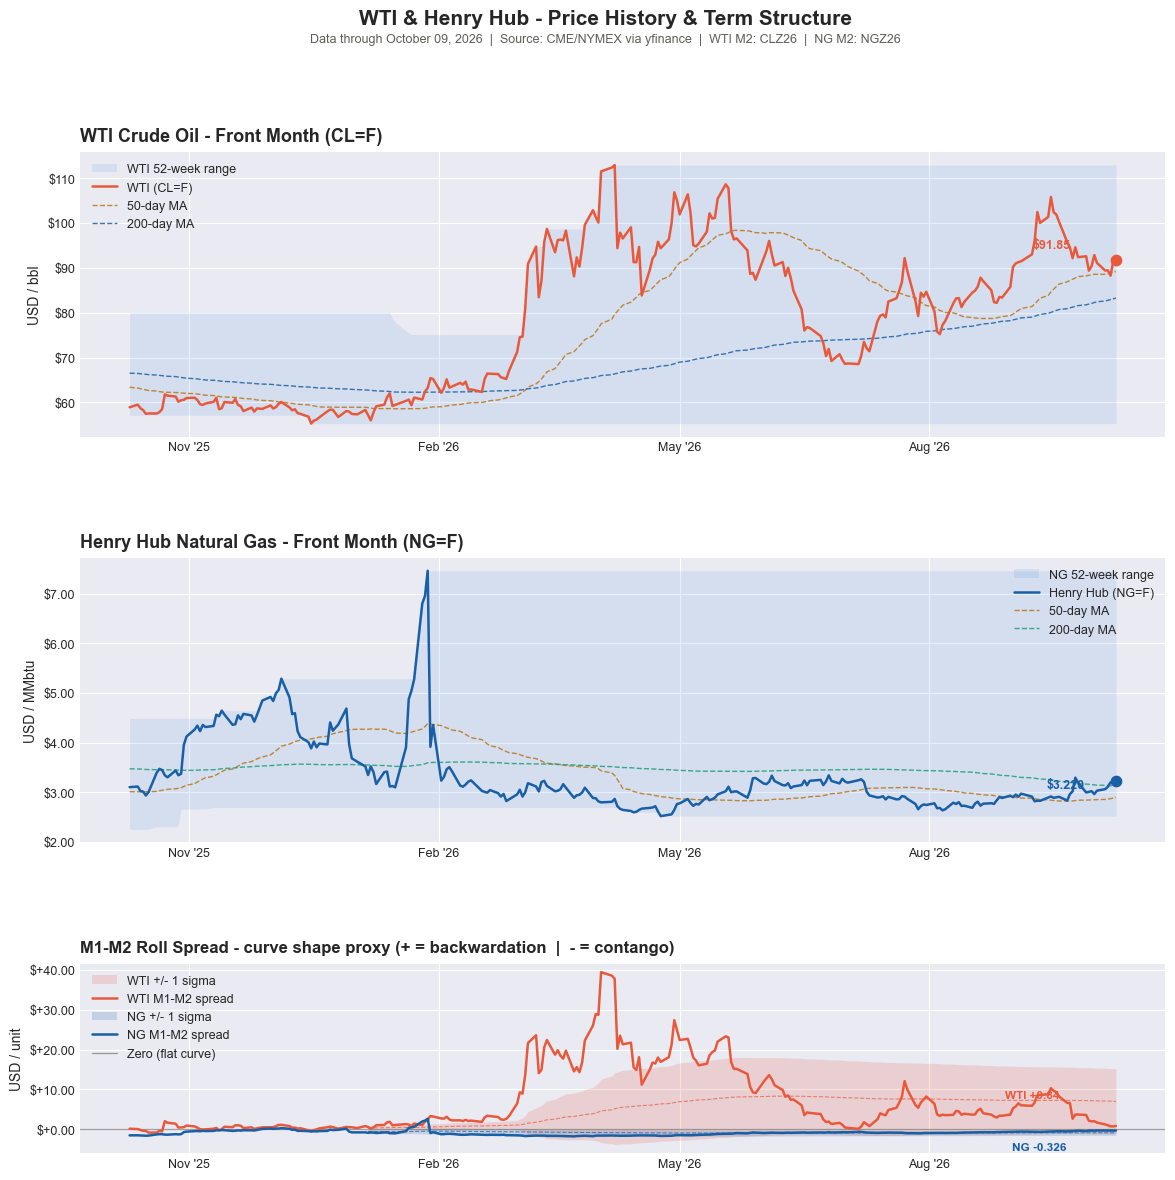


  Chart saved -> c:\Users\mackt\Python Projects\oil_gas_tools\charts\futures_curve_monitor_October_09_2026.png


In [5]:
# ============================================================
# CELL 5 — Three-panel price and curve chart
# ============================================================
# Panel 1 : WTI 2-year price history
#            52-week high/low band, 50/200-day MA
# Panel 2 : Henry Hub 2-year price history
#            same overlays
# Panel 3 : WTI and NG M1-M2 roll spreads
#            rolling mean and +/- 1 sigma bands
#            zero line = contango/backwardation boundary
# ─────────────────────────────────────────────────────────────

# ── Subset to recent window for chart readability ─────────────
cutoff = pd.Timestamp.today() - pd.Timedelta(days=RECENT_DAYS)
df_plot = df_spread[df_spread["date"] >= cutoff].copy()

latest_p = df_plot.iloc[-1]
latest_date = df_spread["date"].max().strftime("%B %d, %Y")

# ── Figure setup ──────────────────────────────────────────────
fig = plt.figure(figsize=(14,13))
gs = GridSpec(
    3, 1,
    figure = fig,
    hspace = 0.48,
    height_ratios=[1.5, 1.5, 1],
)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])
ax3 = fig.add_subplot(gs[2])

# ── Panel 1: WTI price history ────────────────────────────────
ax1.fill_between(
    df_plot["date"],
    df_plot["low_52w_wti"],
    df_plot["high_52w_wti"],
    alpha = 0.12,
    color = "#378ADD",
    label = "WTI 52-week range",
    linewidth = 0,
)
ax1.plot(df_plot["date"], df_plot["wti"],
         color="#E8593C", linewidth=1.8,
         label="WTI (CL=F)", zorder=4)
ax1.plot(df_plot["date"], df_plot["ma50_wti"],
         color="#BA7517", linewidth=1.0, linestyle="--",
         alpha=0.85, label="50-day MA")
ax1.plot(df_plot["date"], df_plot["ma200_wti"],
         color="#185FA5", linewidth=1.0, linestyle="--",
         alpha=0.85, label="200-day MA")

ax1.scatter(
    [df_plot["date"].iloc[-1]], [latest_p["wti"]],
    color="#E8593C", s=55, zorder=6,
)
ax1.annotate(
    f"${latest_p['wti']:.2f}",
    xy = (df_plot["date"].iloc[-1], latest_p["wti"]),
    xytext = (-60, 8),
    textcoords = "offset points",
    fontsize = 9,
    color = "#E8593C",
    fontweight = "bold",
)

ax1.set_title("WTI Crude Oil - Front Month (CL=F)",
              fontsize=13, fontweight="bold", loc="left", pad=8)
ax1.set_ylabel("USD / bbl", fontsize=10)
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}"))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.tick_params(axis="both", labelsize=9)
ax1.legend(fontsize=9, loc="upper left",
           framealpha=0.85, edgecolor="none")

# ── Panel 2: Henry Hub price history ─────────────────────────
ax2.fill_between(
    df_plot["date"],
    df_plot["low_52w_ng"],
    df_plot["high_52w_ng"],
    alpha = 0.12,
    color = "#378ADD",
    label = "NG 52-week range",
    linewidth = 0,
)
ax2.plot(df_plot["date"], df_plot["ng"],
         color="#185FA5", linewidth=1.8,
         label="Henry Hub (NG=F)", zorder=4)
ax2.plot(df_plot["date"], df_plot["ma50_ng"],
         color="#BA7517", linewidth=1.0, linestyle="--",
         alpha=0.85, label="50-day MA")
ax2.plot(df_plot["date"], df_plot["ma200_ng"],
         color="#1D9E75", linewidth=1.0, linestyle="--",
         alpha=0.85, label="200-day MA")

ax2.scatter(
    [df_plot["date"].iloc[-1]], [latest_p["ng"]],
    color="#185FA5", s=55, zorder=6,
)
ax2.annotate(
    f"${latest_p['ng']:.3f}",
    xy = (df_plot["date"].iloc[-1], latest_p["ng"]),
    xytext = (-50, -5),
    textcoords = "offset points",
    fontsize = 9,
    color = "#185FA5",
    fontweight = "bold",
)

ax2.set_title("Henry Hub Natural Gas - Front Month (NG=F)",
              fontsize=13, fontweight="bold", loc="left", pad=8)
ax2.set_ylabel("USD / MMbtu", fontsize=10)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.2f}"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.tick_params(axis="both", labelsize=9)
ax2.legend(fontsize=9, loc="upper right",
           framealpha=0.85, edgecolor="none")

# ── Panel 3: Roll spreads ─────────────────────────────────────
# WTI spread with sigma band
ax3.fill_between(
    df_plot["date"],
    df_plot["wti_roll_spread_mean"] - df_plot["wti_roll_spread_std"],
    df_plot["wti_roll_spread_mean"] + df_plot["wti_roll_spread_std"],
    alpha=0.18, color="#E8593C", linewidth=0,
    label="WTI +/- 1 sigma"
)
ax3.plot(
    df_plot["date"],
    df_plot["wti_roll_spread_mean"],
    color="#E8593C", linewidth=0.8,
    linestyle="--", alpha=0.7,
)
ax3.plot(
    df_plot["date"],
    df_plot["wti_roll_spread"],
    color="#E8593C", linewidth=1.8,
    label="WTI M1-M2 spread", zorder=4,
)

# NG spread with sigma band
ax3.fill_between(
    df_plot["date"],
    df_plot["ng_roll_spread_mean"] - df_plot["ng_roll_spread_std"],
    df_plot["ng_roll_spread_mean"] + df_plot["ng_roll_spread_std"],
    alpha=0.18, color="#185FA5", linewidth=0,
    label="NG +/- 1 sigma",
)
ax3.plot(
    df_plot["date"],
    df_plot["ng_roll_spread_mean"],
    color="#185FA5", linewidth=0.8,
    linestyle="--", alpha=0.7,
)
ax3.plot(
    df_plot["date"],
    df_plot["ng_roll_spread"],
    color="#185FA5", linewidth=1.8,
    label="NG M1-M2 spread", zorder=4,
)

# Zero line — the contango / backwardation boundary
ax3.axhline(
    0, color="#5F5E5A", linewidth=0.9,
    linestyle="-", alpha=0.6, label="Zero (flat curve)",
)

# Annotate latest spread values
ax3.annotate(
    f"WTI {latest_p['wti_roll_spread']:+.2f}",
    xy = (df_plot["date"].iloc[-1],
          latest_p["wti_roll_spread"]),
    xytext = (-80, 20),
    textcoords = "offset points",
    fontsize = 8.5,
    color = "#E8593C",
    fontweight = "bold",
)
ax3.annotate(
    f"NG {latest_p['ng_roll_spread']:+.3f}",
    xy = (df_plot["date"].iloc[-1],
          latest_p["ng_roll_spread"]),
    xytext = (-75, -14),
    textcoords = "offset points",
    fontsize = 8.5,
    color = "#185FA5", 
    fontweight = "bold",
)

ax3.set_title(
    "M1-M2 Roll Spread - curve shape proxy "
    "(+ = backwardation  |  - = contango)",
    fontsize=12, fontweight="bold", loc="left", pad=8,
)
ax3.set_ylabel("USD / unit", fontsize=10)
ax3.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:+.2f}"))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax3.tick_params(axis="both", labelsize=9)
ax3.legend(fontsize=9, loc="upper left",
           framealpha=0.85, edgecolor="none")

# ── Figure-level annotations ──────────────────────────────────
fig.suptitle(
    "WTI & Henry Hub - Price History & Term Structure",
    fontsize=15, fontweight="bold", y=0.99,
)
fig.text(
    0.5, 0.965,
    f"Data through {latest_date}  |  "
    f"Source: CME/NYMEX via yfinance  |  "
    f"WTI M2: {WTI_M2_TICKER.replace('.NYM', '')}  |  "
    f"NG M2: {NG_M2_TICKER.replace('.NYM', '')}",
    ha="center", fontsize=9, color="#5F5E5A",
)

# ── Save and show ─────────────────────────────────────────────
chart_name = (
    f"futures_curve_monitor_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.png"
)
chart_path = CHART_DIR / chart_name
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()
print(f"\n  Chart saved -> {chart_path}")

In [6]:
# ============================================================
# CELL 6 — Term structure signal dashboard
# ============================================================
# Prints a structured dashboard summarizing:
#   Current price vs 52-week range and moving averages
#   M1-M2 roll spread, roll yield, and z-score
#   Curve structure classification
#   WTI/NG ratio and what it implies
#   Plain English interpretation connecting curve shape
#   to storage signals from Tool 3
# ─────────────────────────────────────────────────────────────

latest_s    = df_spread.iloc[-1]
latest_date = df_spread["date"].max().strftime("%B %d, %Y")

# ── Price positioning ─────────────────────────────────────────
wti_vs_ma50  = (latest_s["wti"] / latest_s["ma50_wti"]  - 1) * 100
wti_vs_ma200 = (latest_s["wti"] / latest_s["ma200_wti"] - 1) * 100
ng_vs_ma50   = (latest_s["ng"]  / latest_s["ma50_ng"]   - 1) * 100
ng_vs_ma200  = (latest_s["ng"]  / latest_s["ma200_ng"]  - 1) * 100

wti_52pct = float(latest_s["pctile_52w_wti"])
ng_52pct  = float(latest_s["pctile_52w_ng"])

# ── Curve structure ───────────────────────────────────────────
wti_structure = curve_structure(
    latest_s["wti_roll_spread"],
    latest_s["wti_roll_spread_z"],
)
ng_structure = curve_structure(
    latest_s["ng_roll_spread"],
    latest_s["ng_roll_spread_z"],
)

# ── WTI/NG ratio context ──────────────────────────────────────
ratio_current = latest_s["wti_ng_ratio"]
ratio_avg     = latest_s["ratio_ma60"]
ratio_premium = (ratio_current / ratio_avg - 1) * 100

# ── Roll yield interpretation ─────────────────────────────────
def roll_yield_note(yield_pct: float, commodity: str) -> str:
    if yield_pct > 3:
        return (f"Positive {yield_pct:.1f}%/mo — "
                f"backwardation rewards {commodity} futures longs")
    elif yield_pct > 0:
        return (f"Slightly positive {yield_pct:.1f}%/mo — "
                f"mild backwardation")
    elif yield_pct > -3:
        return (f"Slightly negative {yield_pct:.1f}%/mo — "
                f"mild contango, modest roll cost")
    else:
        return (f"Negative {yield_pct:.1f}%/mo — "
                f"contango penalizes {commodity} futures longs")

# ── Print dashboard ───────────────────────────────────────────
print("=" * 62)
print("FUTURES TERM STRUCTURE DASHBOARD")
print(f"Data through {latest_date}")
print("=" * 62)

print(f"""
  WTI CRUDE OIL (CL=F)
  {'─' * 54}
  Current price    : ${latest_s['wti']:.2f}/bbl
  52-week range    : ${latest_s['low_52w_wti']:.2f} - ${latest_s['high_52w_wti']:.2f}
  52-week position : {wti_52pct:.0f} percentile
  vs 50-day MA     : {wti_vs_ma50:+.1f}%
  vs 200-day MA    : {wti_vs_ma200:+.1f}%
  M1 (front month) : ${latest_s['wti']:.2f}  (CL=F)
  M2 (next month)  : ${latest_s['wti_m2']:.2f}  ({WTI_M2_TICKER})
  M1-M2 spread     : ${latest_s['wti_roll_spread']:+.2f}/bbl
  Roll yield       : {roll_yield_note(latest_s['wti_roll_yield_pct'], 'WTI')}
  Spread z-score   : {latest_s['wti_roll_spread_z']:+.2f} sigma
  Curve structure  : {wti_structure}

  HENRY HUB NATURAL GAS (NG=F)
  {'─' * 54}
  Current price    : ${latest_s['ng']:.3f}/MMbtu
  52-week range    : ${latest_s['low_52w_ng']:.3f} - ${latest_s['high_52w_ng']:.3f}
  52-week position : {ng_52pct:.0f} percentile
  vs 50-day MA     : {ng_vs_ma50:+.1f}%
  vs 200-day MA    : {ng_vs_ma200:+.1f}%
  M1 (front month) : ${latest_s['ng']:.3f}  (NG=F)
  M2 (next month)  : ${latest_s['ng_m2']:.3f}  ({NG_M2_TICKER})
  M1-M2 spread     : ${latest_s['ng_roll_spread']:+.3f}/MMbtu
  Roll yield       : {roll_yield_note(latest_s['ng_roll_yield_pct'], 'NG')}
  Spread z-score   : {latest_s['ng_roll_spread_z']:+.2f} sigma
  Curve structure  : {ng_structure}

  WTI / HENRY HUB RATIO
  {'─' * 54}
  Current ratio    : {ratio_current:.1f}x  (WTI $/bbl / HH $/MMbtu)
  60-day avg ratio : {ratio_avg:.1f}x
  Premium to avg   : {ratio_premium:+.1f}%
  Long-run context : 15-25x is typical; >30x signals oil
                     supply shock or gas oversupply
""")

# ── Plain English interpretation ──────────────────────────────
# Connect curve signals to storage and supply context

wti_interp = (
    "WTI is in steep backwardation — the market is paying a "
    "significant premium for prompt barrels. This signals "
    "near-term physical tightness, likely driven by geopolitical "
    "supply disruption risk. The positive roll yield rewards "
    "holders of front-month futures but the premium is "
    f"historically extreme at {latest_s['wti_roll_spread_z']:+.2f} sigma."
    if latest_s["wti_roll_spread_z"] > 1.5
    else
    "WTI is in moderate backwardation — the market prices "
    "near-term crude supply somewhat tighter than forward "
    "expectations. Positive roll yield supports long positions."
    if latest_s["wti_roll_spread"] > 0
    else
    "WTI is in contango — near-term supply is adequate and the "
    "market is paying a storage premium for forward delivery. "
    "Negative roll yield penalizes passive long futures holders."
)

ng_interp = (
    "Henry Hub is in mild contango — consistent with normal "
    "injection season dynamics. The market sees ample near-term "
    "gas supply and prices forward delivery at a small premium "
    "reflecting storage costs. No near-term tightness signal."
    if -1.0 < latest_s["ng_roll_spread_z"] < 0.5
    else
    "Henry Hub is in backwardation — unusual outside of peak "
    "winter demand. This signals near-term gas tightness, "
    "constructive for prompt Henry Hub prices."
    if latest_s["ng_roll_spread"] > 0
    else
    "Henry Hub is in steep contango — the market is pricing "
    "significant near-term oversupply. Storage incentive is "
    "elevated, consistent with a weak injection season start."
)

ratio_interp = (
    f"The WTI/HH ratio of {ratio_current:.1f}x is "
    f"{ratio_premium:+.0f}% above its 60-day average of "
    f"{ratio_avg:.1f}x. A ratio this elevated reflects an "
    f"oil-specific supply shock rather than broad energy "
    f"tightness — gas fundamentals remain independent of "
    f"the geopolitical crude premium."
    if ratio_current > ratio_avg * 1.15
    else
    f"The WTI/HH ratio of {ratio_current:.1f}x is near its "
    f"60-day average of {ratio_avg:.1f}x, suggesting oil and "
    f"gas are moving broadly in line with each other."
)

# ── Cross-tool context (dynamic — loads latest Tool 3 CSV) ────
import glob

storage_files = sorted(
    glob.glob(str(DATA_DIR / "gas_storage_*.csv")),
    key=lambda f: os.path.getmtime(f)
)

if storage_files:
    df_t3 = pd.read_csv(storage_files[-1], parse_dates=["date"])
    t3_latest    = df_t3.iloc[-1]
    t3_date      = t3_latest["date"].strftime("%B %d, %Y")
    t3_us        = t3_latest["us_total"]
    t3_us_dev    = t3_latest["dev_bcf"]
    t3_us_sigma  = t3_latest["dev_std"]
    t3_sc        = t3_latest["south_total"]
    t3_sc_dev    = t3_latest["sc_dev_bcf"]
    t3_sc_sigma  = t3_latest["sc_dev_std"]

    t3_us_rel = "above" if t3_us_dev >= 0 else "below"
    t3_sc_rel = "below" if t3_sc_dev <  0 else "above"

    # Storage-to-curve consistency check
    # Below-avg storage + contango = inconsistent (bullish lean)
    # Above-avg storage + contango = consistent (bearish lean)
    # Below-avg storage + backwardation = consistent (bullish)
    ng_in_contango = latest_s["ng_roll_spread"] < 0
    us_above_avg   = t3_us_dev >= 0
    sc_above_avg   = t3_sc_dev >= 0

    if ng_in_contango and us_above_avg:
        consistency = (
            "consistent — ample storage supports the "
            "mild contango pricing in the NG curve"
        )
    elif ng_in_contango and not us_above_avg:
        consistency = (
            "worth monitoring — storage is below average "
            "yet the NG curve shows contango, suggesting "
            "the market expects the deficit to refill quickly"
        )
    elif not ng_in_contango and not us_above_avg:
        consistency = (
            "consistent — below-average storage supports "
            "the backwardation pricing in the NG curve"
        )
    else:
        consistency = (
            "mixed — above-average storage despite NG "
            "backwardation; watch for curve normalization"
        )

    cross_tool_note = (
        f"  Tool 3 (gas storage, data through {t3_date}):\n"
        f"  Lower 48: {t3_us:.0f} Bcf  ({t3_us_dev:+.0f} Bcf "
        f"{t3_us_rel} 5yr avg, {t3_us_sigma:+.2f} sigma)\n"
        f"  S. Central: {t3_sc:.0f} Bcf  ({t3_sc_dev:+.0f} Bcf "
        f"{t3_sc_rel} 5yr avg, {t3_sc_sigma:+.2f} sigma)\n"
        f"  Storage vs NG curve: {consistency}.\n"
        f"  WTI backwardation ({latest_s['wti_roll_spread']:+.2f}/bbl, "
        f"{latest_s['wti_roll_spread_z']:+.2f} sigma) is driven by\n"
        f"  geopolitical crude premium — independent of gas fundamentals."
    )
else:
    cross_tool_note = (
        "  Tool 3 CSV not found in data/ folder.\n"
        "  Run gas_storage_tracker.ipynb first to enable\n"
        "  dynamic cross-tool context."
    )

print("=" * 62)
print("  PLAIN ENGLISH SUMMARY")
print("=" * 62)
print(f"""
  WTI: {wti_interp}

  NG:  {ng_interp}

  Ratio: {ratio_interp}

  Cross-tool context:
{cross_tool_note}
""")
print("=" * 62)

FUTURES TERM STRUCTURE DASHBOARD
Data through October 09, 2026

  WTI CRUDE OIL (CL=F)
  ──────────────────────────────────────────────────────
  Current price    : $91.85/bbl
  52-week range    : $55.27 - $112.95
  52-week position : 63 percentile
  vs 50-day MA     : +3.0%
  vs 200-day MA    : +10.3%
  M1 (front month) : $91.85  (CL=F)
  M2 (next month)  : $91.01  (CLZ26.NYM)
  M1-M2 spread     : $+0.84/bbl
  Roll yield       : Slightly positive 0.9%/mo — mild backwardation
  Spread z-score   : -0.75 sigma
  Curve structure  : mild BACKWARDATION

  HENRY HUB NATURAL GAS (NG=F)
  ──────────────────────────────────────────────────────
  Current price    : $3.220/MMbtu
  52-week range    : $2.523 - $7.460
  52-week position : 14 percentile
  vs 50-day MA     : +11.2%
  vs 200-day MA    : +3.1%
  M1 (front month) : $3.220  (NG=F)
  M2 (next month)  : $3.546  (NGZ26.NYM)
  M1-M2 spread     : $-0.326/MMbtu
  Roll yield       : Negative -10.1%/mo — contango penalizes NG futures longs
  Spre

In [7]:
# ============================================================
# CELL 7 — Save data and wrap up
# ============================================================
# Saves the combined price, rolling stats, and spread data
# to CSV for offline reference and cross-tool use.
# ─────────────────────────────────────────────────────────────

# ── Build save DataFrame ──────────────────────────────────────
save_cols = [
    "date",
    "wti", "ma50_wti", "ma200_wti",
    "high_52w_wti", "low_52w_wti", "pctile_52w_wti",
    "ng",  "ma50_ng",  "ma200_ng",
    "high_52w_ng",  "low_52w_ng",  "pctile_52w_ng",
    "wti_ng_ratio", "ratio_ma60",
    "wti_m2", "wti_roll_spread",
    "wti_roll_spread_mean", "wti_roll_spread_std",
    "wti_roll_spread_z", "wti_roll_yield_pct",
    "ng_m2",  "ng_roll_spread",
    "ng_roll_spread_mean", "ng_roll_spread_std",
    "ng_roll_spread_z",  "ng_roll_yield_pct",
]

# Only keep columns that exist in df_spread
save_cols = [c for c in save_cols if c in df_spread.columns]

csv_filename = (
    f"futures_curve_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.csv"
)
csv_path = DATA_DIR / csv_filename
df_spread[save_cols].to_csv(csv_path, index=False)
print(f"  Data saved -> {csv_path}")

# ── Save commentary log ───────────────────────────────────────
commentary_path = DATA_DIR / "futures_curve_commentary_log.txt"

commentary_entry = f"""
{'=' * 62}
FUTURES TERM STRUCTURE COMMENTARY
Run date  : {dt.date.today().strftime('%B %d, %Y')}
Data date : {latest_date}
M2 tickers: WTI = {WTI_M2_TICKER}  |  NG = {NG_M2_TICKER}
{'=' * 62}

METRICS SNAPSHOT
  WTI price        : ${latest_s['wti']:.2f}/bbl
  WTI 52wk pos     : {wti_52pct:.0f} percentile
  WTI vs 50d MA    : {wti_vs_ma50:+.1f}%
  WTI vs 200d MA   : {wti_vs_ma200:+.1f}%
  WTI M1-M2 spread : ${latest_s['wti_roll_spread']:+.2f}/bbl
  WTI roll yield   : {latest_s['wti_roll_yield_pct']:+.1f}%/mo
  WTI spread z     : {latest_s['wti_roll_spread_z']:+.2f} sigma
  WTI curve        : {wti_structure}

  NG price         : ${latest_s['ng']:.3f}/MMbtu
  NG 52wk pos      : {ng_52pct:.0f} percentile
  NG vs 50d MA     : {ng_vs_ma50:+.1f}%
  NG vs 200d MA    : {ng_vs_ma200:+.1f}%
  NG M1-M2 spread  : ${latest_s['ng_roll_spread']:+.3f}/MMbtu
  NG roll yield    : {latest_s['ng_roll_yield_pct']:+.1f}%/mo
  NG spread z      : {latest_s['ng_roll_spread_z']:+.2f} sigma
  NG curve         : {ng_structure}

  WTI/NG ratio     : {ratio_current:.1f}x  (60d avg: {ratio_avg:.1f}x, {ratio_premium:+.0f}%)

PLAIN ENGLISH SUMMARY
  WTI: {wti_interp}

  NG: {ng_interp}

  Ratio: {ratio_interp}

CROSS-TOOL CONTEXT
{cross_tool_note}

"""

with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# ── Next steps reminder ───────────────────────────────────────
today         = dt.date.today()
days_to_fri   = (4 - today.weekday()) % 7
next_friday   = today + dt.timedelta(days=days_to_fri if days_to_fri else 7)
days_to_thu   = (3 - today.weekday()) % 7
next_thursday = today + dt.timedelta(days=days_to_thu if days_to_thu else 7)

# ── Notebook summary ──────────────────────────────────────────
print()
print("=" * 62)
print("  TOOL 4 COMPLETE — Futures Curve & Term Structure")
print("=" * 62)
print(f"""
  What this notebook built:
  {'─' * 54}
  Fetched WTI (CL=F) and Henry Hub (NG=F) price history
  Built rolling 50/200-day MAs and 52-week high/low bands
  Computed WTI/NG energy ratio and 60-day average
  Fetched real M2 contract prices ({WTI_M2_TICKER}, {NG_M2_TICKER})
  Computed M1-M2 roll spread and roll yield
  Classified curve structure with z-score context
  3-panel chart: WTI price, NG price, roll spreads
  Dynamic cross-tool context from Tool 3 storage data
  Signal dashboard with plain English interpretation

  To refresh:
  {'─' * 54}
  Run any time for latest settlement prices
  Prices update during market hours (9am - 2:30pm ET)
  Run Tool 3 first on Thursdays (after 10:30am ET)
  so cross-tool context reflects latest storage data

  M2 ticker maintenance:
  {'─' * 54}
  Current M2 tickers : WTI = {WTI_M2_TICKER}  |  NG = {NG_M2_TICKER}
  WTI M2 expires     : ~Mid-late month, 2026
  NG  M2 expires     : ~Mid-late month, 2026
  Next update needed : around April 25, 2026
  New tickers        : CLN26.NYM (Jul WTI)
                       NGN26.NYM (Jul NG) — verify first
  Check expiry with  : yf.Ticker("CL=F").info
                       yf.Ticker("NG=F").info

  Curve structure reference:
  {'─' * 54}
  Steep backwardation : spread z > +1.5  (extreme tightness)
  Mild backwardation  : spread z 0 to +1.5
  Flat                : spread near zero
  Mild contango       : spread z 0 to -1.5
  Steep contango      : spread z < -1.5  (oversupply signal)

  Cross-tool workflow:
  {'─' * 54}
  Thursday 10:30am ET  -> Run Tool 3 (EIA gas storage)
  Thursday afternoon   -> Run Tool 4 (update cross-tool note)
  Friday  1:00pm ET    -> Run Tool 6 (Baker Hughes rig count)
  Any time             -> Run Tool 2 (WTI/Brent price monitor)
  Any time             -> Run Tool 4 (futures curve refresh)

  Data sources:
  {'─' * 54}
  WTI front month  : CL=F  (CME/NYMEX via yfinance)
  NG  front month  : NG=F  (CME/NYMEX via yfinance)
  WTI second month : {WTI_M2_TICKER} (update monthly)
  NG  second month : {NG_M2_TICKER} (update monthly)
  Month codes      : see futures_contract_month_codes.txt
""")
print("=" * 62)

  Data saved -> c:\Users\mackt\Python Projects\oil_gas_tools\data\futures_curve_October_09_2026.csv
  Commentary logged -> futures_curve_commentary_log.txt

  TOOL 4 COMPLETE — Futures Curve & Term Structure

  What this notebook built:
  ──────────────────────────────────────────────────────
  Fetched WTI (CL=F) and Henry Hub (NG=F) price history
  Built rolling 50/200-day MAs and 52-week high/low bands
  Computed WTI/NG energy ratio and 60-day average
  Fetched real M2 contract prices (CLZ26.NYM, NGZ26.NYM)
  Computed M1-M2 roll spread and roll yield
  Classified curve structure with z-score context
  3-panel chart: WTI price, NG price, roll spreads
  Dynamic cross-tool context from Tool 3 storage data
  Signal dashboard with plain English interpretation

  To refresh:
  ──────────────────────────────────────────────────────
  Run any time for latest settlement prices
  Prices update during market hours (9am - 2:30pm ET)
  Run Tool 3 first on Thursdays (after 10:30am ET)
  so cross-t